# 05 — Backtest and scenarios

**What this notebook shows.** Whether operating the reservoir on the water values of notebook 04 reproduces how Sweden's hydro was actually run in 2015–2025, and what the model says about two questions: how much the Swedish water value moves with the continental price, and how a dry and a wet year play out from the same starting point.

All numbers are computed by `watervalues.simulate` from `data/processed/weekly_se.csv`. This is the same code that `uv run watervalues simulate` runs to write the backtest, its metrics, the scenarios and the report to `outputs/`. It solves the water values once per year, so it takes a little while.

In [1]:
from watervalues import plots
from watervalues.config import PROJECT_ROOT, load_config
from watervalues.data.build import load_weekly
from watervalues.sdp import capacity_gwh
from watervalues.simulate import run_simulations

cfg = load_config()
weekly = load_weekly(PROJECT_ROOT / cfg.data.weekly_csv)
result = run_simulations(cfg, weekly)
report = "\n".join(result.report)
capacity = capacity_gwh(cfg, weekly)
plots.use_style()
print(report[: report.index("Metrics per year")].strip())

Backtest: each ISO year simulated from its observed starting storage with its observed inflow, residual demand and German price; water values recomputed with the year's German price (perfect foresight), the price curve fitted without the year and the year left out of the inflow scenarios
  release grid 10 GWh; weeks with a filled residual demand or German price (left out of the price metrics): 2015-W01, 2015-W50, 2021-W50, 2022-W06


## Method

Week by week, the release is chosen on a grid of 10 GWh steps to minimise this week's cost plus the discounted value of the water left, $C_t(D_t - R) + c^{sp} Sp + \delta\, V_{t+1}(S')$. The value $V_{t+1}$ is interpolated between storage points, and water is spilled only when the reservoir would overflow. The simulated price is $p_t = a_t + b_t (D_t - R_t)$.

Each year of the backtest:
- starts from the storage actually observed at the start of the year;
- uses the inflow, residual demand and German price actually observed that week;
- has its water values solved again with that year's German price. The model therefore knows the continental price in advance, and its only uncertainty is hydrological.

Two precautions keep the backtest honest. The price curve is refitted without the year being tested, and that year is also removed from the inflow scenarios. Neither the price model nor the inflow distribution has seen the year it is judged on.

## Storage: simulated and observed

Text(0.01, 0.98, 'Backtest: simulated and observed storage')

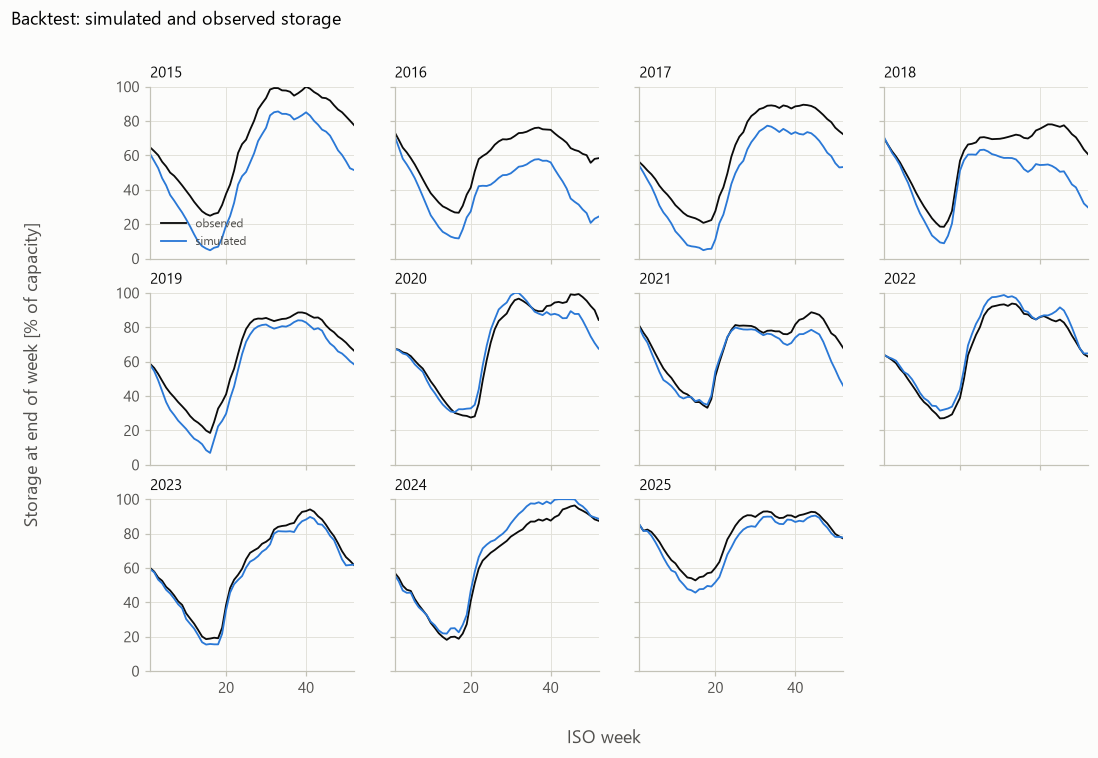

In [2]:
fig = plots.backtest_storage(result.backtest, capacity)
fig.suptitle("Backtest: simulated and observed storage", x=0.01, ha="left")

From 2020 on, the simulated reservoir follows the observed one much more closely through the drawdown, the flood and the refill, though 2021 still ends the autumn too low. In 2015–2019 the model draws the reservoir much deeper in late winter and spring than the producers did, and keeps it lower through the autumn. The shape of each year is right, but the level is too low.

## Price: simulated and observed

Text(0.0, 1.0, 'Backtest: simulated and observed weekly price')

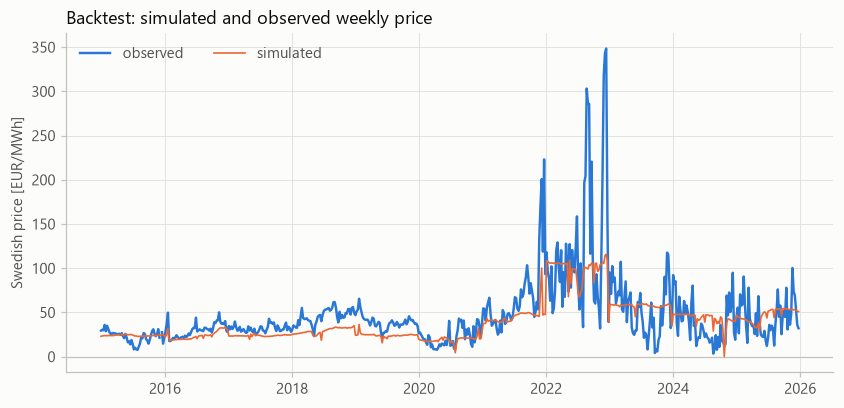

In [3]:
ax = plots.backtest_prices(result.backtest)
ax.set_title("Backtest: simulated and observed weekly price")

The model gets the level of each year right in broad terms, including the jump of 2021–2022, because the German price carries it. Within a year the simulated price is far smoother than the observed one. In the model the price follows the water value, which moves slowly along the storage path. The real weekly price also moves with wind, temperature and the Nordic hydrological balance, which the model holds fixed or leaves out.

## Metrics per year

In [4]:
result.metrics.round(2)

,price_corr,price_mae_eur_mwh,price_bias_eur_mwh,storage_rmse_pct,spill_gwh,observed_price_mean_eur_mwh,simulated_price_mean_eur_mwh
iso_year,,,,,,,
2015,0.16,5.38,1.44,17.76,0.00,22.60,24.05
2016,0.81,6.46,-6.22,20.00,0.00,29.95,23.73
2017,-0.01,8.16,-8.16,15.22,0.00,31.89,23.72
2018,0.69,16.26,-16.26,16.00,0.00,45.43,29.17
2019,0.80,14.97,-14.97,8.00,0.00,39.17,24.19
2020,0.51,7.98,-2.59,7.30,6.32,21.77,19.18
2021,0.73,22.55,-19.96,7.67,0.00,65.73,45.76
2022,0.36,50.91,-27.89,4.04,0.00,126.44,98.55
2023,0.27,23.29,3.90,3.51,0.00,53.40,57.30


- **Price.** Pooled over all years the weekly correlation is high, mostly because the model follows the level shifts between years. Within single years it is much weaker. The errors are largest in 2022, when the observed price spiked far above anything the weekly curve can produce.
- **A bias by period.** The price bias is negative in 2016–2022: the model sells too cheaply. Up to 2019 this matches the storage error, since the deeper drawdown means more water sold. It is close to zero or slightly positive from 2023.
- **Storage.** The error is small from 2020 and largest in 2015–2018.

## Why the backtest misses where it does

These discrepancies are reported as they are; no parameter was tuned to reduce them.

1. **No scarcity premium in the price curve.** The curve is linear in net import, so emptying the reservoir never makes water much dearer than its average value. In the real market prices rise steeply as reservoirs run low, and producers keep a margin. The model drains further because a deep drawdown looks cheap to it. This matches the deeper drawdown of 2015–2019.
2. **Risk neutrality and independent inflows.** The model minimises expected cost, with inflows that are independent from week to week. Real producers are risk averse and know that dry weeks come in runs, and both make them hold more water. Both effects push the same way as the first point.
3. **The price level of 2017–2019.** In those years the Swedish price was above what the curve predicts from the German price (see the residuals by year in notebook 03). The simulated prices of 2018–2019 inherit that error before any operating difference.
4. **One national price and one reservoir.** The model has no Norway, no zones and no transmission limits. The decoupling of the northern and southern zones from 2021, and the Nordic hydrological balance, are outside it.
5. **Perfect foresight of the German price.** This flatters the backtest, so its real out-of-sample accuracy would be lower.

## Scenario: the continental price level

Scenario: German price profile scaled to each annual mean; water value at the mean observed storage of each week [EUR/MWh]
                        water_value_mean_eur_mwh  water_value_min_eur_mwh  water_value_max_eur_mwh  price_mean_eur_mwh
de_price_level_eur_mwh                                                                                                
50.0                                        31.4                     29.9                     32.4                53.6
80.0                                        48.3                     46.3                     49.8                83.8
120.0                                       71.0                     68.2                     73.1               124.1
  slope of the mean water value: 0.57 EUR/MWh per EUR/MWh of German price


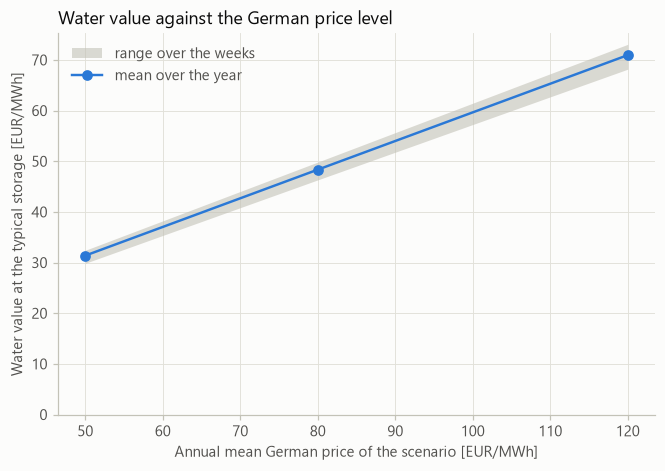

In [5]:
ax = plots.de_price_scenario(result.de_price)
ax.set_title("Water value against the German price level")
print(report[report.index("Scenario: German") : report.index("Scenario: driest")].strip())

The German price profile is scaled to several annual means and the water values are solved again. The water value along the typical storage path moves almost in a straight line with the continental price. Each EUR/MWh on the continent moves the Swedish water value by a little more than half a EUR/MWh.

Two effects of the price curve set this pass-through. The intercept follows the German price nearly one for one, while the proportional slope makes the export discount larger at higher prices. The answer to the question "how much does the Swedish water value move with the continent?" is therefore well below one for one, for a country that exports most weeks.

## Scenario: the driest and the wettest year

Scenario: driest against wettest inflow year from the same initial storage
  dry (2016): inflow 55,436 GWh, release 66,835 GWh, spill 0 GWh; storage 5,187 to 19,959 GWh, ending at 9,963; price mean 51.9 EUR/MWh (weeks 44.9 to 69.5)
  wet (2020): inflow 78,868 GWh, release 74,715 GWh, spill 1 GWh; storage 8,549 to 30,694 GWh, ending at 25,514; price mean 42.0 EUR/MWh (weeks 17.1 to 49.1)


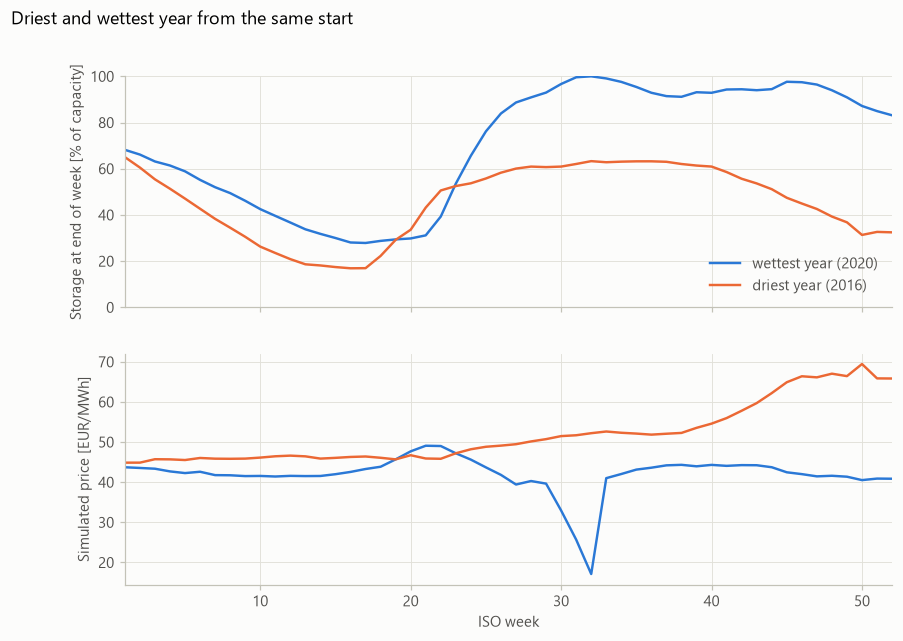

In [6]:
fig = plots.dry_and_wet(result.dry_wet, capacity)
fig.suptitle("Driest and wettest year from the same start", x=0.01, ha="left")
print(report[report.index("Scenario: driest") :].strip())

Both years start from the same storage, with the same demand and German price; only the inflow differs.

- **The wet year** fills the reservoir in the flood. When it is full, water has to be released or spilled, and the price falls sharply before recovering.
- **The dry year** never reaches more than a moderate level. It is drawn down through the autumn and ends the year low, and its price climbs steadily as the water value rises with scarcity.

Over the year the dry case is clearly more expensive, and it hands a much emptier reservoir to the next year.

## Limitations

- **The backtest knows the German price in advance**, so it shows the hydrological side of the model, not a real forecast.
- **The price curve is linear in net import.** It has no scarcity premium at low storage and is extrapolated at large exports; together with risk neutrality, this explains the deeper drawdown of the early years.
- **One national reservoir and price**, with eleven independent inflow years, as in notebook 04.